# Week 2 — Metode Pembanding (ECG Heartbeat Classification, MIT-BIH)

Membandingkan baseline Week 1 (**ResNet18 + GAF**) dengan dua pendekatan berbeda:

| Eksperimen | Pipeline | Pertanyaan |
|---|---|---|
| **A** | GAF (artifact Week 1) → **MobileNetV3-Small** → 5 kelas | Apakah backbone yang jauh lebih ringan sebanding dengan ResNet18 pada GAF? |
| **B** | raw ECG 187 titik → **1D CNN** → 5 kelas | Apakah waveform langsung sebanding dengan pendekatan image-based GAF? |

| Aturan | Keterangan |
|---|---|
| Week 1 | **Hanya dibaca**: `features/*.npy`, GAF HDF5, `history_gaf.csv`, checkpoint/prediksi GAF. Tidak ada yang dilatih ulang, dibuat ulang, atau ditimpa. |
| Output Week 2 | Semua nama file berprefix `week2_` (dicek oleh `week2_path()`); tidak bisa bertabrakan dengan nama Week 1. |
| Run All | **Tidak melatih apa pun.** Semua flag `RUN_* = False` (Section 2). Hasil yang belum ada ditulis `NOT RUN`. |
| Resume | Checkpoint `week2_<tag>_last.chk` disimpan **setiap epoch** (model, optimizer, scheduler, epoch, best F1, history, RNG). Selesai → LOAD; terputus → lanjut dari epoch terakhir saat flag `True`. |
| Urutan | Smoke test (2 epoch, subset) wajib lulus sebelum full training (25 epoch) bisa jalan. |

# Section 1 — Environment

In [60]:
import json
import math
import os
import platform
import random
import sys
import time
from datetime import datetime, timezone
from importlib.metadata import PackageNotFoundError
from importlib.metadata import version as pkg_version

import h5py
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sklearn
import torch
import torch.nn as nn
import torch.optim as optim
import torchvision
from google.colab import drive
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score,
)
from torch.utils.data import DataLoader, Dataset, Subset
from torchvision.models import MobileNet_V3_Small_Weights, mobilenet_v3_small, resnet18

drive.mount("/content/drive")

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("Python      :", sys.version.split()[0])
print("PyTorch     :", torch.__version__)
print("Torchvision :", torchvision.__version__)
print("sklearn     :", sklearn.__version__)
print("DEVICE      :", DEVICE)
if DEVICE.type == "cuda":
    print("GPU         :", torch.cuda.get_device_name(0))
else:
    print("PERINGATAN: GPU tidak aktif. Runtime > Change runtime type > GPU.")


def set_seed(seed):
    """Sama dengan Week 1: seed global + cuDNN deterministik."""
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Python      : 3.13.16
PyTorch     : 2.14.1+cu130
Torchvision : 0.29.1+cu130
sklearn     : 1.6.1
DEVICE      : cuda
GPU         : Tesla T4


# Section 2 — Configuration

## Rancangan eksperimen

```
features/X_train_smote.npy, X_test.npy  (raw ECG, 187 titik; artifact Week 1)
   │
   ├──► [B] 1D CNN (dilatih dari nol) ─────────────────────────────► 5 kelas
   │
   └──► GAF HDF5 224×224 (artifact Week 1, TIDAK dibuat ulang)
           ├──► [Baseline] ResNet18  (Week 1, TIDAK dilatih ulang) ─► 5 kelas
           └──► [A] MobileNetV3-Small (ImageNet, fine-tune) ────────► 5 kelas

Evaluasi semua model: test set resmi Kaggle (21.892 sampel, tanpa SMOTE),
Accuracy, Macro Precision/Recall/F1, confusion matrix, learning curve.
```

## Tabel konfigurasi

| Item | Baseline Week 1 | A: MobileNetV3-Small | B: 1D CNN |
|---|---|---|---|
| Data latih | SMOTE, 152.471 | sama | sama (raw) |
| Data uji | 21.892 (tanpa SMOTE) | sama | sama |
| Input | GAF 1×224×224 → di-*expand* ke 3 channel | sama | raw ECG 1×187 |
| Normalisasi input | tidak ada (GAF ∈ [−1, 1]) | tidak ada | tidak ada (nilai asli dataset) |
| Backbone | ResNet18 ImageNet | MobileNetV3-Small ImageNet | 3 Conv1d, dari nol |
| Bagian yang dilatih | layer3 + layer4 (14×14, 7×7) + FC | `features[4:]` (14×14, 7×7) + classifier | semua |
| Head | FC 512→256→128→5 | classifier asli 576→1024, layer terakhir diganti 1024→5 | Linear 128→5 |
| Loss | CrossEntropy, bobot kelas [1, 2, 1, 2, 1] | sama | sama |
| Optimizer | Adam, β = (0.5, 0.999) | sama | sama |
| Learning rate | backbone 1e-4; FC 1e-4 / 1e-3 / 2e-3 | bagian pretrained 1e-4; layer output baru 2e-3 | 1e-3 |
| Scheduler | ExponentialLR, γ = 0.95 / epoch | sama | sama |
| Epoch / batch / seed | 25 / 64 / 42 | sama | sama |
| Seleksi checkpoint | macro-F1 terbaik pada test set | sama | sama |

## Deviasi (beda dari baseline, dan alasannya)

| # | Deviasi | Alasan |
|---|---|---|
| D1 | Head MobileNet: hanya layer terakhir classifier diganti (1024→5), bukan FC 512-256-128-5 | Sesuai permintaan eksperimen; dimensi fitur MobileNet (576) tidak sama dengan ResNet18 (512), jadi menyalin FC baseline tetap memerlukan pilihan arbitrer. |
| D2 | MobileNet: `features[0:4]` dibekukan, `features[4:]` dilatih | Padanan resolusi dengan baseline: ResNet18 membekukan stage ≥ 28×28 dan melatih stage 14×14 + 7×7. `features[4:]` MobileNetV3-Small persis stage 14×14 + 7×7 (dicek di Section 6). |
| D3 | MobileNet: 2 tingkat LR (1e-4 pretrained, 2e-3 layer baru) | Head hanya punya 2 linear; 2e-3 = LR layer output baseline, 1e-4 = LR bagian pretrained baseline. |
| D4 | 1D CNN: LR tunggal 1e-3, dilatih dari nol, memakai BatchNorm | Tidak ada bobot pretrained 1D; LR 1e-4 baseline dipakai untuk *fine-tuning* bobot pretrained. 1e-3 = default Adam, **tidak di-tuning**. |
| D5 | Tidak ada validation set terpisah | Sama dengan Week 1 (checkpoint dipilih pada test set → cenderung optimistis). Karena itu hasil epoch terakhir juga dilaporkan. |
| D6 | Dropout 0.2 bawaan classifier MobileNetV3 dipertahankan | Bagian dari arsitektur asli torchvision; tidak ditambah/diubah. |

In [61]:
BASE_DIR = "/content/drive/MyDrive/Projek PSD/ECG_Multimodal_Fusion"

FEATURES_DIR = os.path.join(BASE_DIR, "features")
HDF5_DIR = os.path.join(BASE_DIR, "hdf5")
CKPT_DIR = os.path.join(BASE_DIR, "checkpoints")
RESULTS_DIR = os.path.join(BASE_DIR, "outputs", "results")
FIGURES_DIR = os.path.join(BASE_DIR, "outputs", "figures")

# ---- Artifact Week 1 (HANYA DIBACA) ----
GAF_H5 = os.path.join(HDF5_DIR, "hb_data_mit_bih_balanced_3_fixed.hdf5")  # versi FIXED
FEATURE_PATHS = {
    name: os.path.join(FEATURES_DIR, name)
    for name in ("X_train_smote.npy", "y_train_smote.npy", "X_test.npy", "y_test.npy")
}
W1_HISTORY_GAF = os.path.join(RESULTS_DIR, "history_gaf.csv")
W1_CKPT_GAF_F1 = os.path.join(CKPT_DIR, "res_net_gaf_test_f1_best.chk")
W1_PRED_GAF_F1 = os.path.join(RESULTS_DIR, "predictions_gaf_f1.npz")
WEEK1_READONLY = [GAF_H5, *FEATURE_PATHS.values(), W1_HISTORY_GAF, W1_CKPT_GAF_F1, W1_PRED_GAF_F1]

N_TRAIN = 152471
N_TEST = 21892
N_SAMPLES = 187
EXPECTED_TRAIN_COUNTS = {0: 72471, 1: 30000, 2: 20000, 3: 20000, 4: 10000}  # hasil SMOTE Week 1
CLASS_NAMES = ["N", "S", "V", "F", "Q"]
NUM_CLASSES = 5

# ---- Konfigurasi bersama (sama dengan Week 1) ----
SEED = 42
BATCH_SIZE = 64
NUM_EPOCHS_FULL = 25
NUM_EPOCHS_SMOKE = 2
CLASS_WEIGHTS = [1, 2, 1, 2, 1]
ADAM_BETAS = (0.5, 0.999)
LR_GAMMA = 0.95

# ---- Konfigurasi spesifik model (lihat tabel deviasi D2-D4) ----
MOBILENET_TRAINABLE_FROM = 4      # features[4:] dilatih
MOBILENET_LR_PRETRAINED = 1e-4
MOBILENET_LR_NEW_HEAD = 2e-3
CNN1D_LR = 1e-3

# ---- Smoke test: subset kecil, indeks acak tetap (seed 42) ----
SMOKE_N_TRAIN = 2048
SMOKE_N_TEST = 1024

# ---- FLAG (default False: Run All tidak melatih apa pun) ----
RUN_MOBILENET_SMOKE = False
RUN_MOBILENET_FULL = False
RUN_1D_SMOKE = False
RUN_1D_FULL = True

NOT_RUN = "NOT RUN"
NOT_RECORDED = "NOT RECORDED"

os.makedirs(CKPT_DIR, exist_ok=True)
os.makedirs(RESULTS_DIR, exist_ok=True)
os.makedirs(FIGURES_DIR, exist_ok=True)


def week2_path(directory, filename):
    """Semua file yang DITULIS notebook ini lewat fungsi ini -> dijamin berprefix week2_."""
    if not filename.startswith("week2_"):
        raise ValueError(f"Nama file output Week 2 harus berprefix 'week2_': {filename}")
    return os.path.join(directory, filename)


set_seed(SEED)
print("BASE_DIR:", BASE_DIR)
print("Flags   :", dict(RUN_MOBILENET_SMOKE=RUN_MOBILENET_SMOKE, RUN_MOBILENET_FULL=RUN_MOBILENET_FULL,
                        RUN_1D_SMOKE=RUN_1D_SMOKE, RUN_1D_FULL=RUN_1D_FULL))

BASE_DIR: /content/drive/MyDrive/Projek PSD/ECG_Multimodal_Fusion
Flags   : {'RUN_MOBILENET_SMOKE': False, 'RUN_MOBILENET_FULL': False, 'RUN_1D_SMOKE': False, 'RUN_1D_FULL': True}


# Section 3 — Artifact Validation

Validasi ringan (validasi penuh sudah dilakukan di Week 1): file ada, shape, dtype, finite, distribusi label, label HDF5 = label `features/*.npy`, dan sampel blok GAF (awal, tengah, ujung SMOTE).
Dibuat juga **snapshot** (ukuran + waktu modifikasi) artifact Week 1; Section 17 memeriksa bahwa tidak ada yang berubah.

In [62]:
missing = [p for p in [GAF_H5, *FEATURE_PATHS.values()] if not os.path.exists(p)]
if missing:
    raise FileNotFoundError(
        "Artifact Week 1 berikut TIDAK ditemukan:\n  - " + "\n  - ".join(missing)
        + "\nPastikan Drive ter-mount dan BASE_DIR benar. Week 2 tidak membuat ulang artifact."
    )

problems = []

# ---- features/*.npy (mmap: tidak menyalin ke RAM)
FEATURE_SHAPES = {
    "X_train_smote.npy": (N_TRAIN, N_SAMPLES),
    "y_train_smote.npy": (N_TRAIN,),
    "X_test.npy": (N_TEST, N_SAMPLES),
    "y_test.npy": (N_TEST,),
}
print("[features]")
for fname, shape in FEATURE_SHAPES.items():
    arr = np.load(FEATURE_PATHS[fname], mmap_mode="r")
    line = f"  {fname:18s} shape={arr.shape} dtype={arr.dtype}"
    if arr.shape != shape:
        problems.append(f"{fname}: shape {arr.shape} != {shape}")
    if fname.startswith("X_"):
        if not np.isfinite(arr).all():
            problems.append(f"{fname}: mengandung NaN/Inf")
        line += f" min={float(arr.min()):.4f} max={float(arr.max()):.4f}"
    print(line)

y_train_ref = np.asarray(np.load(FEATURE_PATHS["y_train_smote.npy"]), dtype=np.int64)
y_test_ref = np.asarray(np.load(FEATURE_PATHS["y_test.npy"]), dtype=np.int64)

counts = dict(zip(*[a.tolist() for a in np.unique(y_train_ref, return_counts=True)]))
if counts != EXPECTED_TRAIN_COUNTS:
    problems.append(f"y_train_smote: distribusi {counts} != {EXPECTED_TRAIN_COUNTS}")
if not set(np.unique(y_test_ref).tolist()) <= set(range(NUM_CLASSES)):
    problems.append("y_test: label di luar 0..4")
print("  label train:", counts)
print("  label test :", dict(zip(*[a.tolist() for a in np.unique(y_test_ref, return_counts=True)])))

# ---- GAF HDF5
print("\n[GAF]", os.path.basename(GAF_H5))
with h5py.File(GAF_H5, "r") as f:
    spec = {"x_train": (N_TRAIN, 224, 224), "y_train": (N_TRAIN,),
            "x_test": (N_TEST, 224, 224), "y_test": (N_TEST,)}
    for key, shape in spec.items():
        if key not in f:
            problems.append(f"GAF: dataset '{key}' tidak ada")
            continue
        print(f"  {key:8s} shape={f[key].shape} dtype={f[key].dtype}")
        if f[key].shape != shape:
            problems.append(f"GAF/{key}: shape {f[key].shape} != {shape}")
    if not problems:
        if not np.array_equal(f["y_train"][:], y_train_ref):
            problems.append("GAF/y_train != features/y_train_smote.npy")
        if not np.array_equal(f["y_test"][:], y_test_ref):
            problems.append("GAF/y_test != features/y_test.npy")
        for key in ("x_train", "x_test"):
            n = len(f[key])
            for start in (0, n // 2, max(n - 64, 0)):
                block = f[key][start:start + 64]
                if not np.isfinite(block).all():
                    problems.append(f"GAF/{key}[{start}:{start + 64}]: NaN/Inf")
                elif block.min() < -1.01 or block.max() > 1.01:
                    problems.append(f"GAF/{key}[{start}:{start + 64}]: di luar [-1, 1]")

if problems:
    raise RuntimeError("Validasi artifact GAGAL:\n  - " + "\n  - ".join(problems))
print("\nArtifact data VALID.")

# ---- Artifact referensi baseline (tidak wajib; jika tidak ada -> baseline NOT RUN)
print("\n[Referensi baseline Week 1]")
for p in (W1_HISTORY_GAF, W1_CKPT_GAF_F1, W1_PRED_GAF_F1):
    print(f"  {'ADA  ' if os.path.exists(p) else 'TIDAK'} {os.path.relpath(p, BASE_DIR)}")


def snapshot(paths):
    return {p: (os.stat(p).st_size, os.stat(p).st_mtime_ns) for p in paths if os.path.exists(p)}


WEEK1_SNAPSHOT = snapshot(WEEK1_READONLY)
print(f"\nSnapshot {len(WEEK1_SNAPSHOT)} artifact Week 1 disimpan (dicek ulang di Section 17).")

[features]
  X_train_smote.npy  shape=(152471, 187) dtype=float32 min=0.0000 max=1.0000
  y_train_smote.npy  shape=(152471,) dtype=float64
  X_test.npy         shape=(21892, 187) dtype=float32 min=0.0000 max=1.0000
  y_test.npy         shape=(21892,) dtype=int32
  label train: {0: 72471, 1: 30000, 2: 20000, 3: 20000, 4: 10000}
  label test : {0: 18118, 1: 556, 2: 1448, 3: 162, 4: 1608}

[GAF] hb_data_mit_bih_balanced_3_fixed.hdf5
  x_train  shape=(152471, 224, 224) dtype=float32
  y_train  shape=(152471,) dtype=int32
  x_test   shape=(21892, 224, 224) dtype=float32
  y_test   shape=(21892,) dtype=int32

Artifact data VALID.

[Referensi baseline Week 1]
  ADA   outputs/results/history_gaf.csv
  ADA   checkpoints/res_net_gaf_test_f1_best.chk
  ADA   outputs/results/predictions_gaf_f1.npz

Snapshot 8 artifact Week 1 disimpan (dicek ulang di Section 17).


# Section 4 — Dataset/DataLoader

- `GafHdf5Dataset`: sama dengan `Dataset_Hdf5` Week 1 (satu file, dibuka *lazy* per sampel). Output `1×224×224`.
- `RawEcgDataset`: membaca `features/*.npy` dengan `mmap_mode="r"` (tidak ada salinan dataset). Output `1×187`.
- Smoke test memakai `Subset` dengan indeks acak tetap (seed 42, terurut agar akses HDF5 efisien).

In [63]:
class GafHdf5Dataset(Dataset):
    def __init__(self, h5_path, split):
        self.h5_path = h5_path
        self.split = split
        self.file = None
        with h5py.File(h5_path, "r") as f:
            self.length = len(f[f"x_{split}"])

    def __len__(self):
        return self.length

    def __getitem__(self, index):
        if self.file is None:
            self.file = h5py.File(self.h5_path, "r")
        image = np.asarray(self.file[f"x_{self.split}"][index], dtype=np.float32)[None]  # 1x224x224
        label = int(self.file[f"y_{self.split}"][index])
        return torch.from_numpy(image), torch.tensor(label, dtype=torch.long)

    def __del__(self):
        if getattr(self, "file", None) is not None:
            self.file.close()


class RawEcgDataset(Dataset):
    def __init__(self, x_path, y_path):
        self.x = np.load(x_path, mmap_mode="r")
        self.y = np.load(y_path, mmap_mode="r")

    def __len__(self):
        return len(self.y)

    def __getitem__(self, index):
        signal = np.array(self.x[index], dtype=np.float32)[None]  # 1x187 (salinan 1 baris; mmap read-only)
        return torch.from_numpy(signal), torch.tensor(int(self.y[index]), dtype=torch.long)


def make_loader(dataset, shuffle):
    return DataLoader(dataset, batch_size=BATCH_SIZE, shuffle=shuffle, num_workers=0,
                      pin_memory=DEVICE.type == "cuda")


_rng = np.random.default_rng(SEED)
SMOKE_IDX_TRAIN = np.sort(_rng.choice(N_TRAIN, size=min(SMOKE_N_TRAIN, N_TRAIN), replace=False))
SMOKE_IDX_TEST = np.sort(_rng.choice(N_TEST, size=min(SMOKE_N_TEST, N_TEST), replace=False))

gaf_train_ds = GafHdf5Dataset(GAF_H5, "train")
gaf_test_ds = GafHdf5Dataset(GAF_H5, "test")
raw_train_ds = RawEcgDataset(FEATURE_PATHS["X_train_smote.npy"], FEATURE_PATHS["y_train_smote.npy"])
raw_test_ds = RawEcgDataset(FEATURE_PATHS["X_test.npy"], FEATURE_PATHS["y_test.npy"])

LOADERS = {
    "gaf": (make_loader(gaf_train_ds, True), make_loader(gaf_test_ds, False)),
    "gaf_smoke": (make_loader(Subset(gaf_train_ds, SMOKE_IDX_TRAIN), True),
                  make_loader(Subset(gaf_test_ds, SMOKE_IDX_TEST), False)),
    "raw": (make_loader(raw_train_ds, True), make_loader(raw_test_ds, False)),
    "raw_smoke": (make_loader(Subset(raw_train_ds, SMOKE_IDX_TRAIN), True),
                  make_loader(Subset(raw_test_ds, SMOKE_IDX_TEST), False)),
}

for name, (tr, te) in LOADERS.items():
    x, y = next(iter(te))
    print(f"{name:10s} train={len(tr.dataset):>7,d} test={len(te.dataset):>6,d} | "
          f"batch x={tuple(x.shape)} {x.dtype} y={tuple(y.shape)} finite={bool(torch.isfinite(x).all())}")

# label dari Dataset harus sama dengan referensi
assert int(gaf_test_ds[N_TEST - 1][1]) == int(y_test_ref[-1]) == int(raw_test_ds[N_TEST - 1][1])

gaf        train=152,471 test=21,892 | batch x=(64, 1, 224, 224) torch.float32 y=(64,) finite=True
gaf_smoke  train=  2,048 test= 1,024 | batch x=(64, 1, 224, 224) torch.float32 y=(64,) finite=True
raw        train=152,471 test=21,892 | batch x=(64, 1, 187) torch.float32 y=(64,) finite=True
raw_smoke  train=  2,048 test= 1,024 | batch x=(64, 1, 187) torch.float32 y=(64,) finite=True


## 4.1 Fungsi bersama (training, evaluasi, metrik)

Satu definisi untuk Model A dan B. Logika per epoch, metrik, dan seleksi checkpoint **sama dengan `train()` Week 1**:
train → evaluasi test set → `scheduler.step()` → simpan *best* bila macro-F1 naik.
Tambahan Week 2 (tidak mengubah angka): checkpoint `last` setiap epoch untuk resume, waktu per epoch, penulisan atomik (`.tmp` lalu rename).

In [64]:
def compute_metrics(y_true, y_pred):
    """Fungsi metrik tunggal untuk semua model (sama dengan Week 1)."""
    return {
        "accuracy": accuracy_score(y_true, y_pred),
        "precision": precision_score(y_true, y_pred, average="macro", zero_division=0),
        "recall": recall_score(y_true, y_pred, average="macro", zero_division=0),
        "f1": f1_score(y_true, y_pred, average="macro", zero_division=0),
    }


def to_model_input(inputs):
    """GAF 1 channel -> 3 channel (expand, sama dengan Week 1). Raw ECG (B,1,187) tidak diubah."""
    inputs = inputs.to(DEVICE, non_blocking=True)
    if inputs.dim() == 4 and inputs.shape[1] == 1:
        inputs = inputs.expand(-1, 3, -1, -1)
    return inputs


def count_params(net):
    return {"total": sum(p.numel() for p in net.parameters()),
            "trainable": sum(p.numel() for p in net.parameters() if p.requires_grad)}


def make_criterion():
    return nn.CrossEntropyLoss(weight=torch.tensor(CLASS_WEIGHTS, dtype=torch.float32, device=DEVICE))


def evaluate(net, loader, criterion):
    """Loss + prediksi pada loader (tanpa gradien)."""
    net.eval()
    total_loss, total, y_true, y_pred = 0.0, 0, [], []
    with torch.no_grad():
        for inputs, labels in loader:
            inputs, labels = to_model_input(inputs), labels.to(DEVICE, non_blocking=True)
            outputs = net(inputs)
            loss_value = criterion(outputs, labels).item()
            if not math.isfinite(loss_value):
                raise FloatingPointError(f"Loss evaluasi non-finite: {loss_value}")
            total_loss += loss_value * labels.size(0)
            total += labels.size(0)
            y_true.append(labels.cpu().numpy())
            y_pred.append(outputs.argmax(1).cpu().numpy())
    return total_loss / total, np.concatenate(y_true), np.concatenate(y_pred)


def smoke_check(net, criterion, loader):
    """Satu batch: forward, shape output, loss finite, backward, gradien finite & tidak nol."""
    net.train()
    inputs, labels = next(iter(loader))
    inputs, labels = to_model_input(inputs), labels.to(DEVICE)
    outputs = net(inputs)
    assert outputs.shape == (labels.shape[0], NUM_CLASSES), f"shape output {tuple(outputs.shape)}"
    loss = criterion(outputs, labels)
    assert math.isfinite(loss.item()), f"loss non-finite: {loss.item()}"
    loss.backward()
    grads = [p.grad for p in net.parameters() if p.requires_grad]
    assert all(g is not None and torch.isfinite(g).all() for g in grads), "gradien None/NaN/Inf"
    assert any(g.abs().sum() > 0 for g in grads), "semua gradien nol"
    net.zero_grad(set_to_none=True)
    print(f"smoke_check OK | input {tuple(inputs.shape)} -> output {tuple(outputs.shape)} | "
          f"loss {loss.item():.4f} | {len(grads)} tensor gradien finite")


def ckpt_paths(tag):
    return {
        "last": week2_path(CKPT_DIR, f"week2_{tag}_last.chk"),
        "best": week2_path(CKPT_DIR, f"week2_{tag}_best.chk"),
        "history": week2_path(RESULTS_DIR, f"week2_history_{tag}.csv"),
    }


def atomic_torch_save(obj, path):
    tmp = path + ".tmp"
    torch.save(obj, tmp)
    os.replace(tmp, path)


def training_status(tag, num_epochs):
    """'COMPLETE', 'PARTIAL k/n', atau NOT_RUN — dibaca dari checkpoint last (bukan dari flag)."""
    path = ckpt_paths(tag)["last"]
    if not os.path.exists(path):
        return NOT_RUN
    ckpt = torch.load(path, map_location="cpu", weights_only=False)
    if ckpt["num_epochs"] != num_epochs:
        raise ValueError(f"{path}: num_epochs={ckpt['num_epochs']} != {num_epochs}")
    return "COMPLETE" if ckpt["epoch"] >= num_epochs else f"PARTIAL {ckpt['epoch']}/{num_epochs}"


def load_history(tag):
    return pd.read_csv(ckpt_paths(tag)["history"])


def train_resumable(tag, build_fn, train_loader, test_loader, num_epochs):
    """Training resumable. Jika week2_<tag>_last.chk ada -> lanjut dari epoch tersimpan (RNG ikut dipulihkan)."""
    paths = ckpt_paths(tag)
    set_seed(SEED)
    net, criterion, optimizer = build_fn()
    scheduler = optim.lr_scheduler.ExponentialLR(optimizer, gamma=LR_GAMMA)
    history, start_epoch, best_f1, best_epoch = [], 0, -1.0, None

    if os.path.exists(paths["last"]):
        ckpt = torch.load(paths["last"], map_location=DEVICE, weights_only=False)
        if ckpt["num_epochs"] != num_epochs:
            raise ValueError(f"Checkpoint {tag} dibuat untuk {ckpt['num_epochs']} epoch, bukan {num_epochs}.")
        net.load_state_dict(ckpt["model_state_dict"])
        optimizer.load_state_dict(ckpt["optimizer_state_dict"])
        scheduler.load_state_dict(ckpt["scheduler_state_dict"])
        history, start_epoch = ckpt["history"], ckpt["epoch"]
        best_f1, best_epoch = ckpt["best_f1"], ckpt["best_epoch"]
        if os.path.exists(paths["best"]):  # jika terputus di antara simpan best dan simpan last
            best_meta = torch.load(paths["best"], map_location="cpu", weights_only=False)
            if best_meta["f1"] > best_f1:
                best_f1, best_epoch = best_meta["f1"], best_meta["epoch"]
        random.setstate(ckpt["rng"]["python"])
        np.random.set_state(ckpt["rng"]["numpy"])
        torch.set_rng_state(ckpt["rng"]["torch"])
        if DEVICE.type == "cuda" and ckpt["rng"]["cuda"] is not None:
            torch.cuda.set_rng_state_all(ckpt["rng"]["cuda"])
        print(f"RESUME {tag}: {start_epoch}/{num_epochs} epoch sudah selesai (best F1 {best_f1:.4f} @ {best_epoch}).")

    for epoch in range(start_epoch, num_epochs):
        t0 = time.time()

        # ---------------- TRAIN ----------------
        net.train()
        running_loss, train_total, train_correct = 0.0, 0, 0
        for inputs, labels in train_loader:
            inputs, labels = to_model_input(inputs), labels.to(DEVICE, non_blocking=True)
            optimizer.zero_grad()
            outputs = net(inputs)
            loss = criterion(outputs, labels)
            loss_value = loss.item()
            if not math.isfinite(loss_value):
                raise FloatingPointError(f"{tag}: loss train non-finite ({loss_value}) di epoch {epoch + 1}")
            loss.backward()
            optimizer.step()
            running_loss += loss_value * labels.size(0)
            train_total += labels.size(0)
            train_correct += (outputs.argmax(1) == labels).sum().item()

        # ---------------- TEST ----------------
        test_loss, y_true, y_pred = evaluate(net, test_loader, criterion)
        m = compute_metrics(y_true, y_pred)
        scheduler.step()
        if DEVICE.type == "cuda":
            torch.cuda.synchronize()
        epoch_time = time.time() - t0

        history.append({
            "epoch": epoch + 1,
            "train_loss": running_loss / train_total,
            "train_accuracy": train_correct / train_total,
            "test_loss": test_loss,
            "test_accuracy": m["accuracy"],
            "test_precision": m["precision"],
            "test_recall": m["recall"],
            "test_f1": m["f1"],
            "epoch_time_sec": epoch_time,
        })

        # ---------------- CHECKPOINT ----------------
        if m["f1"] > best_f1:
            best_f1, best_epoch = m["f1"], epoch + 1
            atomic_torch_save({"epoch": epoch + 1, "model_state_dict": net.state_dict(),
                               "f1": m["f1"], "metrics": m}, paths["best"])
        atomic_torch_save({
            "epoch": epoch + 1,
            "num_epochs": num_epochs,
            "model_state_dict": net.state_dict(),
            "optimizer_state_dict": optimizer.state_dict(),
            "scheduler_state_dict": scheduler.state_dict(),
            "best_f1": best_f1,
            "best_epoch": best_epoch,
            "history": history,
            "rng": {"python": random.getstate(), "numpy": np.random.get_state(),
                    "torch": torch.get_rng_state(),
                    "cuda": torch.cuda.get_rng_state_all() if DEVICE.type == "cuda" else None},
        }, paths["last"])
        pd.DataFrame(history).to_csv(paths["history"], index=False)

        h = history[-1]
        print(f"[{tag}] Epoch {epoch + 1}/{num_epochs} | Train Loss {h['train_loss']:.4f} | "
              f"Train Acc {h['train_accuracy']:.4f} | Test Loss {h['test_loss']:.4f} | "
              f"Test Acc {h['test_accuracy']:.4f} | P {h['test_precision']:.4f} | "
              f"R {h['test_recall']:.4f} | F1 {h['test_f1']:.4f} | {epoch_time:.0f}s")

    return net, history


def run_smoke(tag, build_fn, loaders_key, enabled):
    """Smoke test: smoke_check 1 batch + 2 epoch pada subset. Hasil valid -> LOAD."""
    status = training_status(tag, NUM_EPOCHS_SMOKE)
    if status == "COMPLETE":
        print(f"LOAD: smoke test {tag} sudah selesai (tidak dijalankan ulang).")
    elif enabled:
        train_loader, test_loader = LOADERS[loaders_key]
        set_seed(SEED)
        net, criterion, _ = build_fn()
        smoke_check(net, criterion, train_loader)
        del net
        train_resumable(tag, build_fn, train_loader, test_loader, NUM_EPOCHS_SMOKE)
    else:
        print(f"{status}: smoke test {tag}. Set flag menjadi True di Section 2 untuk menjalankan.")
        return None
    h = load_history(tag)
    ok = len(h) == NUM_EPOCHS_SMOKE and bool(np.isfinite(h.to_numpy()).all())
    print("SMOKE TEST", "LULUS" if ok else "GAGAL", "(loss/metrik finite, 2 epoch, evaluasi berjalan)")
    display(h.round(4))
    return h if ok else None


def run_full(tag, smoke_tag, build_fn, loaders_key, enabled):
    """Full training. COMPLETE -> LOAD; flag True -> TRAIN/RESUME (setelah smoke lulus); selain itu NOT RUN/PARTIAL."""
    status = training_status(tag, NUM_EPOCHS_FULL)
    if status == "COMPLETE":
        print(f"LOAD: {tag} sudah {NUM_EPOCHS_FULL} epoch (tidak dilatih ulang).")
    elif enabled:
        if training_status(smoke_tag, NUM_EPOCHS_SMOKE) != "COMPLETE":
            raise RuntimeError(f"Smoke test {smoke_tag} belum lulus. Jalankan smoke test lebih dulu.")
        train_resumable(tag, build_fn, *LOADERS[loaders_key], NUM_EPOCHS_FULL)
    else:
        print(f"{status}: {tag}. Set flag menjadi True di Section 2 untuk "
              + ("melanjutkan (resume)." if status.startswith("PARTIAL") else "melatih."))
        return None
    h = load_history(tag)
    display(h.round(4))
    return h


def measure_inference(net, input_shape, n_warmup=5, n_repeat=20):
    """Biaya komputasi model saja (tanpa I/O Drive): batch sintetis BATCH_SIZE pada DEVICE."""
    net.eval()
    x = torch.zeros((BATCH_SIZE, *input_shape), device=DEVICE)
    if len(input_shape) == 3 and input_shape[0] == 1:
        x = x.expand(-1, 3, -1, -1)
    with torch.no_grad():
        for _ in range(n_warmup):
            net(x)
        if DEVICE.type == "cuda":
            torch.cuda.synchronize()
        t0 = time.perf_counter()
        for _ in range(n_repeat):
            net(x)
        if DEVICE.type == "cuda":
            torch.cuda.synchronize()
    ms_batch = (time.perf_counter() - t0) / n_repeat * 1000
    return {"ms_per_batch": ms_batch, "ms_per_sample": ms_batch / BATCH_SIZE, "batch_size": BATCH_SIZE,
            "device": str(DEVICE)}


def evaluate_best(tag, build_fn, test_loader):
    """Metrik test set dari week2_<tag>_best.chk. Prediksi tersimpan -> LOAD; selain itu inferensi (tanpa training)."""
    paths = ckpt_paths(tag)
    if not os.path.exists(paths["best"]):
        return None
    meta = torch.load(paths["best"], map_location="cpu", weights_only=False)
    pred_path = week2_path(RESULTS_DIR, f"week2_predictions_{tag}_best.npz")

    cached = False
    if os.path.exists(pred_path):
        d = np.load(pred_path)
        cached = int(d["ckpt_epoch"]) == meta["epoch"] and np.array_equal(d["y_true"], y_test_ref)
    if cached:
        y_true, y_pred = d["y_true"], d["y_pred"]
        print(f"LOAD  {os.path.basename(pred_path)}")
    else:
        net = build_fn()[0]
        net.load_state_dict(meta["model_state_dict"])
        _, y_true, y_pred = evaluate(net, test_loader, make_criterion())
        got = compute_metrics(y_true, y_pred)["f1"]
        if abs(got - meta["f1"]) > 1e-4:
            raise RuntimeError(f"{tag}: macro-F1 rekomputasi {got:.4f} != checkpoint {meta['f1']:.4f}")
        tmp = pred_path[:-4] + ".tmp.npz"
        np.savez(tmp, y_true=y_true, y_pred=y_pred, ckpt_epoch=np.array(meta["epoch"]))
        os.replace(tmp, pred_path)
        print(f"SAVE  {os.path.basename(pred_path)}")
    return {**compute_metrics(y_true, y_pred), "epoch": int(meta["epoch"]), "y_true": y_true, "y_pred": y_pred}


def final_epoch_metrics(history):
    if history is None:
        return None
    last = history.iloc[-1]
    return {"accuracy": last["test_accuracy"], "precision": last["test_precision"],
            "recall": last["test_recall"], "f1": last["test_f1"], "epoch": int(last["epoch"])}

# Section 5 — Baseline Reference

Baseline **tidak dilatih ulang dan tidak diinferensi ulang**. Nilai dibaca dari artifact Week 1:

1. `predictions_gaf_f1.npz` (dari Section 20 Week 1) → metrik + confusion matrix checkpoint macro-F1 terbaik, bila epoch-nya cocok dengan `res_net_gaf_test_f1_best.chk`.
2. Jika prediksi tidak ada: baris `history_gaf.csv` pada epoch checkpoint tersebut (metrik sama, confusion matrix `NOT RUN`).
3. Epoch terakhir: baris terakhir `history_gaf.csv`.

Jumlah parameter dihitung dari arsitektur yang sama dengan `build_baseline()` Week 1 (tanpa memuat bobot; jumlah parameter tidak bergantung bobot).

In [65]:
def build_week1_resnet18_arch():
    """Arsitektur identik dengan build_baseline() Week 1, hanya untuk hitung parameter & waktu inferensi."""
    net = resnet18(weights=None)
    for p in net.parameters():
        p.requires_grad = False
    for p in [*net.layer3.parameters(), *net.layer4.parameters()]:
        p.requires_grad = True
    net.fc = nn.Sequential(nn.Linear(512, 256, bias=False), nn.ReLU(), nn.Linear(256, 128), nn.ReLU(),
                           nn.Linear(128, NUM_CLASSES))
    return net.to(DEVICE)


baseline_history = None
if os.path.exists(W1_HISTORY_GAF):
    baseline_history = pd.read_csv(W1_HISTORY_GAF)
    if len(baseline_history) != NUM_EPOCHS_FULL:
        print(f"PERINGATAN: history_gaf.csv berisi {len(baseline_history)} epoch, bukan {NUM_EPOCHS_FULL}.")

baseline_best = None
baseline_source = NOT_RUN
if os.path.exists(W1_CKPT_GAF_F1):
    w1_meta = torch.load(W1_CKPT_GAF_F1, map_location="cpu", weights_only=False)
    w1_epoch = int(w1_meta["epoch"])
    if os.path.exists(W1_PRED_GAF_F1):
        d = np.load(W1_PRED_GAF_F1)
        if int(d["ckpt_epoch"]) == w1_epoch and np.array_equal(d["y_true"], y_test_ref):
            baseline_best = {**compute_metrics(d["y_true"], d["y_pred"]), "epoch": w1_epoch,
                             "y_true": d["y_true"], "y_pred": d["y_pred"]}
            baseline_source = "predictions_gaf_f1.npz"
    if baseline_best is None and baseline_history is not None:
        row = baseline_history[baseline_history["epoch"] == w1_epoch]
        if len(row):
            r = row.iloc[0]
            baseline_best = {"accuracy": r["test_accuracy"], "precision": r["test_precision"],
                             "recall": r["test_recall"], "f1": r["test_f1"], "epoch": w1_epoch,
                             "y_true": None, "y_pred": None}
            baseline_source = f"history_gaf.csv (epoch {w1_epoch}; confusion matrix tidak tersedia)"
    if baseline_best is not None and abs(baseline_best["f1"] - float(w1_meta["f1"])) > 1e-4:
        raise RuntimeError("Macro-F1 baseline dari prediksi/history tidak cocok dengan checkpoint Week 1.")

baseline_final = final_epoch_metrics(baseline_history)

_net = build_week1_resnet18_arch()
BASELINE_PARAMS = count_params(_net)
del _net

print("Sumber metrik baseline (best F1):", baseline_source)
if baseline_best is not None:
    print({k: round(float(v), 4) for k, v in baseline_best.items() if k in ("accuracy", "precision", "recall", "f1")},
          "| epoch", baseline_best["epoch"])
print("Epoch terakhir:", NOT_RUN if baseline_final is None else {k: round(float(v), 4) for k, v in baseline_final.items()})
print("Parameter ResNet18 baseline:", BASELINE_PARAMS)

Sumber metrik baseline (best F1): predictions_gaf_f1.npz
{'accuracy': 0.9886, 'precision': 0.9523, 'recall': 0.9197, 'f1': 0.9353} | epoch 21
Epoch terakhir: {'accuracy': 0.9886, 'precision': 0.9419, 'recall': 0.9185, 'f1': 0.9299, 'epoch': 25.0}
Parameter ResNet18 baseline: {'total': 11341125, 'trainable': 10658053}


# Section 6 — Model A: MobileNetV3-Small

- `torchvision.models.mobilenet_v3_small`, bobot `IMAGENET1K_V1`.
- Input: GAF 1×224×224 di-*expand* ke 3 channel (identik dengan baseline; tanpa normalisasi ImageNet, sama dengan baseline).
- Dibekukan: `features[0:4]` (stem + stage 112/56/28 px). Dilatih: `features[4:]` (stage 14×14 dan 7×7) + classifier. Padanan dengan ResNet18 baseline yang melatih layer3 (14×14) + layer4 (7×7).
- Classifier: `Linear(576,1024) → Hardswish → Dropout(0.2) → Linear(1024, 5)` (hanya layer terakhir yang diganti).
- Catatan: seperti baseline, BatchNorm pada bagian beku tetap memperbarui *running statistics* dalam mode train.

In [66]:
def build_mobilenet(pretrained=True):
    net = mobilenet_v3_small(weights=MobileNet_V3_Small_Weights.IMAGENET1K_V1 if pretrained else None)
    for p in net.parameters():
        p.requires_grad = False
    for p in net.features[MOBILENET_TRAINABLE_FROM:].parameters():
        p.requires_grad = True
    net.classifier[3] = nn.Linear(net.classifier[3].in_features, NUM_CLASSES)  # baru, trainable
    for p in net.classifier.parameters():
        p.requires_grad = True
    net = net.to(DEVICE)

    optimizer = optim.Adam(
        [
            {"params": net.features[MOBILENET_TRAINABLE_FROM:].parameters(), "lr": MOBILENET_LR_PRETRAINED},
            {"params": net.classifier[0].parameters(), "lr": MOBILENET_LR_PRETRAINED},
            {"params": net.classifier[3].parameters(), "lr": MOBILENET_LR_NEW_HEAD},
        ],
        betas=ADAM_BETAS,
    )
    return net, make_criterion(), optimizer


MOBILENET_CONFIG = {
    "model": "torchvision mobilenet_v3_small",
    "weights": "IMAGENET1K_V1",
    "input": "GAF 1x224x224 expand ke 3 channel, tanpa normalisasi",
    "frozen": f"features[0:{MOBILENET_TRAINABLE_FROM}]",
    "trainable": f"features[{MOBILENET_TRAINABLE_FROM}:] + classifier",
    "classifier": "Linear(576,1024) -> Hardswish -> Dropout(0.2) -> Linear(1024,5)",
    "optimizer": f"Adam betas={ADAM_BETAS}",
    "lr": {"features[4:]": MOBILENET_LR_PRETRAINED, "classifier[0]": MOBILENET_LR_PRETRAINED,
           "classifier[3] (baru)": MOBILENET_LR_NEW_HEAD},
    "scheduler": f"ExponentialLR(gamma={LR_GAMMA})",
    "loss": f"CrossEntropyLoss(weight={CLASS_WEIGHTS})",
}

# ---- Model construction check (tanpa training)
_net, _crit, _opt = build_mobilenet()
MOBILENET_PARAMS = count_params(_net)
_x = torch.zeros(2, 3, 224, 224, device=DEVICE)
_net.eval()
with torch.no_grad():
    for i, block in enumerate(_net.features):
        _x = block(_x)
        state = "train" if any(p.requires_grad for p in block.parameters()) else "beku"
        print(f"features[{i:2d}] -> {tuple(_x.shape[1:])}  {state}")
    print("output:", tuple(_net(torch.zeros(2, 3, 224, 224, device=DEVICE)).shape))
for name, g in zip(["features[4:]", "classifier[0]", "classifier[3]"], _opt.param_groups):
    print(f"{name:14s} params={sum(p.numel() for p in g['params']):>9,d} lr={g['lr']}")
print("Parameter MobileNetV3-Small:", MOBILENET_PARAMS)
del _net, _crit, _opt, _x
if DEVICE.type == "cuda":
    torch.cuda.empty_cache()

features[ 0] -> (16, 112, 112)  beku
features[ 1] -> (16, 56, 56)  beku
features[ 2] -> (24, 28, 28)  beku
features[ 3] -> (24, 28, 28)  beku
features[ 4] -> (40, 14, 14)  train
features[ 5] -> (40, 14, 14)  train
features[ 6] -> (40, 14, 14)  train
features[ 7] -> (48, 14, 14)  train
features[ 8] -> (48, 14, 14)  train
features[ 9] -> (96, 7, 7)  train
features[10] -> (96, 7, 7)  train
features[11] -> (96, 7, 7)  train
features[12] -> (576, 7, 7)  train
output: (2, 5)
features[4:]   params=  916,520 lr=0.0001
classifier[0]  params=  590,848 lr=0.0001
classifier[3]  params=    5,125 lr=0.002
Parameter MobileNetV3-Small: {'total': 1522981, 'trainable': 1512493}


# Section 7 — Smoke Test Model A

`RUN_MOBILENET_SMOKE` (Section 2). Isi: `smoke_check` 1 batch (forward, shape `B×5`, loss finite, backward, gradien finite) lalu **2 epoch** pada subset 2.048 train / 1.024 test, termasuk evaluasi. Tag `mobilenet_smoke` (terpisah dari full training).

In [67]:
hist_mobilenet_smoke = run_smoke("mobilenet_smoke", build_mobilenet, "gaf_smoke", RUN_MOBILENET_SMOKE)

LOAD: smoke test mobilenet_smoke sudah selesai (tidak dijalankan ulang).
SMOKE TEST LULUS (loss/metrik finite, 2 epoch, evaluasi berjalan)


,epoch,train_loss,train_accuracy,test_loss,test_accuracy,test_precision,test_recall,test_f1,epoch_time_sec
0,1,0.7903,0.7144,1.4420,0.2256,0.2913,0.2101,0.0954,456.4024
1,2,0.3954,0.8657,1.1037,0.5879,0.5214,0.2524,0.1996,14.0207


# Section 8 — Full Training Model A

`RUN_MOBILENET_FULL` (Section 2). 25 epoch, data penuh, tag `mobilenet`. Jika Colab terputus: jalankan ulang notebook dari atas dengan flag `True` → training **dilanjutkan** dari epoch terakhir di `week2_mobilenet_last.chk`.

In [68]:
hist_mobilenet = run_full("mobilenet", "mobilenet_smoke", build_mobilenet, "gaf", RUN_MOBILENET_FULL)

LOAD: mobilenet sudah 25 epoch (tidak dilatih ulang).


,epoch,train_loss,train_accuracy,test_loss,test_accuracy,test_precision,test_recall,test_f1,epoch_time_sec
0,1,0.1238,0.9560,0.1197,0.9624,0.7916,0.9208,0.8399,1023.3205
1,2,0.0406,0.9852,0.0947,0.9765,0.8532,0.9175,0.8786,743.8741
2,3,0.0257,0.9909,0.1204,0.9716,0.8273,0.9289,0.8665,750.0220
3,4,0.0182,0.9935,0.1206,0.9741,0.8726,0.9025,0.8837,760.4355
4,5,0.0136,0.9952,0.1171,0.9821,0.8825,0.9148,0.8918,762.1430
5,6,0.0115,0.9958,0.1294,0.9810,0.8831,0.9022,0.8909,765.1557
6,7,0.0092,0.9968,0.1166,0.9820,0.8944,0.9124,0.9029,764.2794
7,8,0.0078,0.9973,0.1373,0.9845,0.9258,0.9035,0.9139,764.3910
8,9,0.0070,0.9978,0.1282,0.9837,0.9121,0.9023,0.9069,761.1289
9,10,0.0058,0.9980,0.1300,0.9840,0.9207,0.9093,0.9145,762.1143


# Section 9 — Evaluation Model A

Checkpoint macro-F1 terbaik (`week2_mobilenet_best.chk`) diinferensi pada test set penuh (sekali; prediksi disimpan ke `week2_predictions_mobilenet_best.npz`), dicek terhadap F1 yang tercatat saat training. Hanya inferensi, bukan training.

In [69]:
mobilenet_best = evaluate_best("mobilenet", build_mobilenet, LOADERS["gaf"][1]) if hist_mobilenet is not None else None
mobilenet_final = final_epoch_metrics(hist_mobilenet)

if mobilenet_best is None:
    print(NOT_RUN)
else:
    print(f"Best macro-F1 checkpoint: epoch {mobilenet_best['epoch']}")
    print(classification_report(mobilenet_best["y_true"], mobilenet_best["y_pred"],
                                target_names=CLASS_NAMES, digits=4, zero_division=0))

LOAD  week2_predictions_mobilenet_best.npz
Best macro-F1 checkpoint: epoch 24
              precision    recall  f1-score   support

           N     0.9902    0.9960    0.9931     18118
           S     0.8996    0.8058    0.8501       556
           V     0.9754    0.9572    0.9662      1448
           F     0.8165    0.7963    0.8063       162
           Q     0.9950    0.9851    0.9900      1608

    accuracy                         0.9863     21892
   macro avg     0.9353    0.9081    0.9211     21892
weighted avg     0.9860    0.9863    0.9861     21892



# Section 10 — Model B: 1D CNN

Raw ECG `1×187`, dilatih dari nol.

| Blok | Layer | Output |
|---|---|---|
| 1 | Conv1d(1→32, k=7, pad=3) → BatchNorm → ReLU → MaxPool1d(2) | 32×93 |
| 2 | Conv1d(32→64, k=5, pad=2) → BatchNorm → ReLU → MaxPool1d(2) | 64×46 |
| 3 | Conv1d(64→128, k=3, pad=1) → BatchNorm → ReLU → AdaptiveAvgPool1d(1) | 128×1 |
| Classifier | Flatten → Linear(128→5) | 5 |

- 3 convolution layer, kernel 7/5/3 (lebih lebar di awal untuk menangkap morfologi QRS/P/T, menyempit di layer dalam), channel 32/64/128.
- Pooling: MaxPool1d(2) setelah blok 1–2, global average pooling setelah blok 3.
- Dropout: **tidak digunakan** (model kecil, data latih 152 ribu sampel).
- Optimizer/loss/scheduler sama dengan baseline; LR 1e-3 (deviasi D4).

In [70]:
class ECG1DCNN(nn.Module):
    def __init__(self, num_classes=NUM_CLASSES):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv1d(1, 32, kernel_size=7, padding=3), nn.BatchNorm1d(32), nn.ReLU(), nn.MaxPool1d(2),
            nn.Conv1d(32, 64, kernel_size=5, padding=2), nn.BatchNorm1d(64), nn.ReLU(), nn.MaxPool1d(2),
            nn.Conv1d(64, 128, kernel_size=3, padding=1), nn.BatchNorm1d(128), nn.ReLU(),
            nn.AdaptiveAvgPool1d(1),
        )
        self.classifier = nn.Linear(128, num_classes)

    def forward(self, x):
        return self.classifier(self.features(x).flatten(1))


def build_1dcnn():
    net = ECG1DCNN().to(DEVICE)
    optimizer = optim.Adam(net.parameters(), lr=CNN1D_LR, betas=ADAM_BETAS)
    return net, make_criterion(), optimizer


CNN1D_CONFIG = {
    "model": "ECG1DCNN (3x Conv1d)",
    "input": "raw ECG 1x187 (features/*.npy), tanpa normalisasi tambahan",
    "conv_layers": 3,
    "kernels": [7, 5, 3],
    "channels": [32, 64, 128],
    "batchnorm": True,
    "pooling": "MaxPool1d(2) setelah conv1 & conv2; AdaptiveAvgPool1d(1) setelah conv3",
    "dropout": None,
    "classifier": "Linear(128,5)",
    "pretrained": False,
    "optimizer": f"Adam betas={ADAM_BETAS}",
    "lr": CNN1D_LR,
    "scheduler": f"ExponentialLR(gamma={LR_GAMMA})",
    "loss": f"CrossEntropyLoss(weight={CLASS_WEIGHTS})",
}

# ---- Model construction check (tanpa training)
_net, _crit, _opt = build_1dcnn()
CNN1D_PARAMS = count_params(_net)
_x = torch.zeros(2, 1, N_SAMPLES, device=DEVICE)
_net.eval()
with torch.no_grad():
    for layer in _net.features:
        _x = layer(_x)
        if isinstance(layer, (nn.MaxPool1d, nn.AdaptiveAvgPool1d)):
            print(f"{layer.__class__.__name__:18s} -> {tuple(_x.shape[1:])}")
    print("output:", tuple(_net(torch.zeros(2, 1, N_SAMPLES, device=DEVICE)).shape))
print("Parameter 1D CNN:", CNN1D_PARAMS)
del _net, _crit, _opt, _x

MaxPool1d          -> (32, 93)
MaxPool1d          -> (64, 46)
AdaptiveAvgPool1d  -> (128, 1)
output: (2, 5)
Parameter 1D CNN: {'total': 36357, 'trainable': 36357}


# Section 11 — Smoke Test Model B

`RUN_1D_SMOKE` (Section 2). Sama dengan Section 7: `smoke_check` 1 batch + 2 epoch pada subset (indeks sama dengan smoke test Model A). Tag `1dcnn_smoke`.

In [71]:
hist_1dcnn_smoke = run_smoke("1dcnn_smoke", build_1dcnn, "raw_smoke", RUN_1D_SMOKE)

LOAD: smoke test 1dcnn_smoke sudah selesai (tidak dijalankan ulang).
SMOKE TEST LULUS (loss/metrik finite, 2 epoch, evaluasi berjalan)


,epoch,train_loss,train_accuracy,test_loss,test_accuracy,test_precision,test_recall,test_f1,epoch_time_sec
0,1,1.2245,0.5083,1.1915,0.7812,0.2553,0.2604,0.2470,0.3585
1,2,0.9602,0.6440,0.9766,0.6201,0.3451,0.5404,0.3055,0.3119


# Section 12 — Full Training Model B

`RUN_1D_FULL` (Section 2). 25 epoch, data penuh, tag `1dcnn`. Resume sama dengan Section 8.

In [72]:
hist_1dcnn = run_full("1dcnn", "1dcnn_smoke", build_1dcnn, "raw", RUN_1D_FULL)

[1dcnn] Epoch 1/25 | Train Loss 0.3437 | Train Acc 0.8808 | Test Loss 0.5600 | Test Acc 0.7994 | P 0.6082 | R 0.8516 | F1 0.6245 | 14s
[1dcnn] Epoch 2/25 | Train Loss 0.2035 | Train Acc 0.9287 | Test Loss 0.2161 | Test Acc 0.9345 | P 0.7835 | R 0.7834 | F1 0.7616 | 13s
[1dcnn] Epoch 3/25 | Train Loss 0.1684 | Train Acc 0.9404 | Test Loss 1.0688 | Test Acc 0.5812 | P 0.7395 | R 0.7744 | F1 0.6568 | 15s
[1dcnn] Epoch 4/25 | Train Loss 0.1470 | Train Acc 0.9485 | Test Loss 0.2034 | Test Acc 0.9350 | P 0.7057 | R 0.8807 | F1 0.7501 | 13s
[1dcnn] Epoch 5/25 | Train Loss 0.1321 | Train Acc 0.9536 | Test Loss 0.4089 | Test Acc 0.8482 | P 0.6544 | R 0.9064 | F1 0.6781 | 14s
[1dcnn] Epoch 6/25 | Train Loss 0.1181 | Train Acc 0.9587 | Test Loss 0.1104 | Test Acc 0.9677 | P 0.8282 | R 0.8992 | F1 0.8585 | 13s
[1dcnn] Epoch 7/25 | Train Loss 0.1072 | Train Acc 0.9627 | Test Loss 0.2752 | Test Acc 0.8987 | P 0.7794 | R 0.8760 | F1 0.7842 | 14s
[1dcnn] Epoch 8/25 | Train Loss 0.0993 | Train Acc 0.96

,epoch,train_loss,train_accuracy,test_loss,test_accuracy,test_precision,test_recall,test_f1,epoch_time_sec
0,1,0.3437,0.8808,0.5600,0.7994,0.6082,0.8516,0.6245,13.6825
1,2,0.2035,0.9287,0.2161,0.9345,0.7835,0.7834,0.7616,13.1987
2,3,0.1684,0.9404,1.0688,0.5812,0.7395,0.7744,0.6568,14.9013
3,4,0.1470,0.9485,0.2034,0.9350,0.7057,0.8807,0.7501,13.2081
4,5,0.1321,0.9536,0.4089,0.8482,0.6544,0.9064,0.6781,13.9621
5,6,0.1181,0.9587,0.1104,0.9677,0.8282,0.8992,0.8585,13.2423
6,7,0.1072,0.9627,0.2752,0.8987,0.7794,0.8760,0.7842,13.5421
7,8,0.0993,0.9654,1.6691,0.4834,0.6156,0.8303,0.5695,13.1520
8,9,0.0922,0.9677,0.2332,0.9190,0.7164,0.9157,0.7716,13.2444
9,10,0.0851,0.9700,0.5882,0.8117,0.6091,0.8946,0.6353,13.7393


# Section 13 — Evaluation Model B

In [73]:
cnn1d_best = evaluate_best("1dcnn", build_1dcnn, LOADERS["raw"][1]) if hist_1dcnn is not None else None
cnn1d_final = final_epoch_metrics(hist_1dcnn)

if cnn1d_best is None:
    print(NOT_RUN)
else:
    print(f"Best macro-F1 checkpoint: epoch {cnn1d_best['epoch']}")
    print(classification_report(cnn1d_best["y_true"], cnn1d_best["y_pred"],
                                target_names=CLASS_NAMES, digits=4, zero_division=0))

SAVE  week2_predictions_1dcnn_best.npz
Best macro-F1 checkpoint: epoch 25
              precision    recall  f1-score   support

           N     0.9874    0.9869    0.9871     18118
           S     0.7116    0.7410    0.7260       556
           V     0.9623    0.9330    0.9474      1448
           F     0.6971    0.8951    0.7838       162
           Q     0.9931    0.9826    0.9878      1608

    accuracy                         0.9761     21892
   macro avg     0.8703    0.9077    0.8864     21892
weighted avg     0.9770    0.9761    0.9764     21892



# Section 14 — Comparison

**Tabel 1** — checkpoint macro-F1 terbaik (protokol Tabel A Week 1; dipilih pada test set → optimistis).
**Tabel 2** — epoch terakhir (tanpa seleksi pada test set).
**Tabel 3** — kompleksitas. Waktu inferensi = biaya komputasi model saja (batch sintetis 64 di GPU yang sama, tanpa I/O Drive), sehingga adil antar model; baseline juga diukur dengan arsitektur yang sama (bobot tidak memengaruhi waktu). Waktu training baseline tidak tercatat di Week 1 → `NOT RECORDED`.

Faktor yang **sama**: dataset MIT-BIH, split train/test Kaggle, artifact SMOTE, seed 42, 5 kelas, loss berbobot, optimizer Adam (β sama), scheduler, epoch, batch size, fungsi metrik `compute_metrics()`, protokol seleksi checkpoint.
Faktor yang **berbeda**: representasi input (GAF vs raw), arsitektur, jumlah parameter, biaya komputasi, LR/bagian yang dilatih (deviasi D1–D4).

In [74]:
METHODS = [
    # (label, input, best, final, params, history, tag)
    ("Week 1 ResNet18 + GAF", "GAF", baseline_best, baseline_final, BASELINE_PARAMS, None, None),
    ("Week 2 MobileNetV3-Small + GAF", "GAF", mobilenet_best, mobilenet_final, MOBILENET_PARAMS, hist_mobilenet, "mobilenet"),
    ("Week 2 1D CNN", "Raw ECG", cnn1d_best, cnn1d_final, CNN1D_PARAMS, hist_1dcnn, "1dcnn"),
]


def metric_row(label, inp, m):
    return {"Method": label, "Input": inp,
            "Checkpoint epoch": NOT_RUN if m is None else m["epoch"],
            "Accuracy": NOT_RUN if m is None else float(m["accuracy"]),
            "Macro Precision": NOT_RUN if m is None else float(m["precision"]),
            "Macro Recall": NOT_RUN if m is None else float(m["recall"]),
            "Macro F1": NOT_RUN if m is None else float(m["f1"])}


table_best = pd.DataFrame([metric_row(l, i, b) for l, i, b, *_ in METHODS])
table_final = pd.DataFrame([metric_row(l, i, f) for l, i, _, f, *_ in METHODS])

# ---- Kompleksitas
INFERENCE = {
    "Week 1 ResNet18 + GAF": (build_week1_resnet18_arch, (1, 224, 224)),
    "Week 2 MobileNetV3-Small + GAF": (lambda: build_mobilenet(pretrained=False)[0], (1, 224, 224)),
    "Week 2 1D CNN": (lambda: build_1dcnn()[0], (1, N_SAMPLES)),
}
rows_c = []
for label, inp, best, _, params, hist, tag in METHODS:
    t = measure_inference(INFERENCE[label][0](), INFERENCE[label][1])
    full = hist is not None and len(hist) == NUM_EPOCHS_FULL
    rows_c.append({
        "Method": label, "Input": inp,
        "Params total": params["total"], "Params trainable": params["trainable"],
        "Train time total (min)": float(hist["epoch_time_sec"].sum() / 60) if full else (NOT_RUN if tag else NOT_RECORDED),
        "Train time / epoch (s)": float(hist["epoch_time_sec"].mean()) if full else (NOT_RUN if tag else NOT_RECORDED),
        "Inference ms / batch64": t["ms_per_batch"],
        "Inference ms / sample": t["ms_per_sample"],
    })
table_complexity = pd.DataFrame(rows_c)
INFERENCE_DEVICE = str(DEVICE) + (f" ({torch.cuda.get_device_name(0)})" if DEVICE.type == "cuda" else "")
if DEVICE.type == "cuda":
    torch.cuda.empty_cache()

print("TABEL 1 — checkpoint macro-F1 terbaik")
display(table_best.round(4))
print("\nTABEL 2 — epoch terakhir")
display(table_final.round(4))
print(f"\nTABEL 3 — kompleksitas (inferensi diukur di {INFERENCE_DEVICE})")
display(table_complexity.round(3))

# ---- Simpan satu CSV gabungan
comparison = table_best.rename(columns=lambda c: c if c in ("Method", "Input") else f"best_{c}")
comparison = comparison.merge(
    table_final.drop(columns="Input").rename(columns=lambda c: c if c == "Method" else f"final_{c}"), on="Method")
comparison = comparison.merge(table_complexity.drop(columns="Input"), on="Method")
COMPARISON_CSV = week2_path(RESULTS_DIR, "week2_comparison.csv")
comparison.to_csv(COMPARISON_CSV, index=False)
print("Saved:", COMPARISON_CSV)

TABEL 1 — checkpoint macro-F1 terbaik


,Method,Input,Checkpoint epoch,Accuracy,Macro Precision,Macro Recall,Macro F1
0,Week 1 ResNet18 + GAF,GAF,21,0.9886,0.9523,0.9197,0.9353
1,Week 2 MobileNetV3-Small + GAF,GAF,24,0.9863,0.9353,0.9081,0.9211
2,Week 2 1D CNN,Raw ECG,25,0.9761,0.8703,0.9077,0.8864



TABEL 2 — epoch terakhir


,Method,Input,Checkpoint epoch,Accuracy,Macro Precision,Macro Recall,Macro F1
0,Week 1 ResNet18 + GAF,GAF,25,0.9886,0.9419,0.9185,0.9299
1,Week 2 MobileNetV3-Small + GAF,GAF,25,0.9855,0.9226,0.9104,0.9160
2,Week 2 1D CNN,Raw ECG,25,0.9761,0.8703,0.9077,0.8864



TABEL 3 — kompleksitas (inferensi diukur di cuda (Tesla T4))


,Method,Input,Params total,Params trainable,Train time total (min),Train time / epoch (s),Inference ms / batch64,Inference ms / sample
0,Week 1 ResNet18 + GAF,GAF,11341125,10658053,NOT RECORDED,NOT RECORDED,51.028,0.797
1,Week 2 MobileNetV3-Small + GAF,GAF,1522981,1512493,322.04061,772.897464,13.744,0.215
2,Week 2 1D CNN,Raw ECG,36357,36357,5.604615,13.451075,0.745,0.012


Saved: /content/drive/MyDrive/Projek PSD/ECG_Multimodal_Fusion/outputs/results/week2_comparison.csv


# Section 15 — Confusion Matrix

Dari checkpoint macro-F1 terbaik. Kiri: jumlah sampel. Recall per kelas (baris dinormalisasi) ditampilkan di tabel, karena kelas minoritas (S, F) menentukan Macro F1.

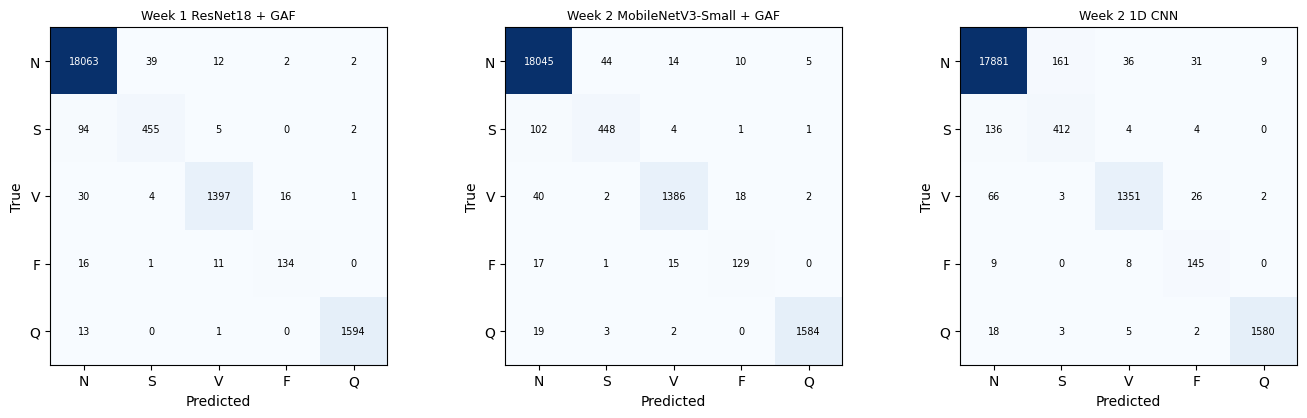

Recall per kelas:


,Method,N,S,V,F,Q
0,Week 1 ResNet18 + GAF,0.9970,0.8183,0.9648,0.8272,0.9913
1,Week 2 MobileNetV3-Small + GAF,0.9960,0.8058,0.9572,0.7963,0.9851
2,Week 2 1D CNN,0.9869,0.7410,0.9330,0.8951,0.9826


In [75]:
cm_models = {label: best for label, _, best, *_ in METHODS
             if best is not None and best.get("y_pred") is not None}
recall_rows = []

if not cm_models:
    print(NOT_RUN, "— belum ada prediksi untuk confusion matrix.")
else:
    fig_cm, axes = plt.subplots(1, len(cm_models), figsize=(4.6 * len(cm_models), 4.2), squeeze=False)
    for ax, (label, m) in zip(axes[0], cm_models.items()):
        cm = confusion_matrix(m["y_true"], m["y_pred"], labels=range(NUM_CLASSES))
        ax.imshow(cm, cmap="Blues")
        ax.set_title(label, fontsize=9)
        ax.set_xticks(range(NUM_CLASSES)); ax.set_xticklabels(CLASS_NAMES)
        ax.set_yticks(range(NUM_CLASSES)); ax.set_yticklabels(CLASS_NAMES)
        ax.set_xlabel("Predicted"); ax.set_ylabel("True")
        for i in range(NUM_CLASSES):
            for j in range(NUM_CLASSES):
                ax.text(j, i, cm[i, j], ha="center", va="center", fontsize=7,
                        color="white" if cm[i, j] > cm.max() / 2 else "black")
        recall_rows.append({"Method": label, **{c: cm[i, i] / cm[i].sum() for i, c in enumerate(CLASS_NAMES)}})
        if label != "Week 1 ResNet18 + GAF":  # CSV hanya untuk model Week 2
            tag = "mobilenet" if "MobileNet" in label else "1dcnn"
            pd.DataFrame(cm, index=CLASS_NAMES, columns=CLASS_NAMES).to_csv(
                week2_path(RESULTS_DIR, f"week2_confusion_{tag}.csv"))
    plt.tight_layout()
    fig_cm.savefig(week2_path(FIGURES_DIR, "week2_confusion_matrices.png"), dpi=150, bbox_inches="tight")
    plt.show()

missing_cm = [label for label, _, best, *_ in METHODS if label not in cm_models]
if missing_cm:
    print("Tanpa confusion matrix (NOT RUN / prediksi tidak tersedia):", missing_cm)

per_class_recall = pd.DataFrame(recall_rows)
if len(per_class_recall):
    print("Recall per kelas:")
    display(per_class_recall.round(4))

# Section 16 — Learning Curves

Dari `history_gaf.csv` (Week 1, dibaca saja) dan `week2_history_<tag>.csv`. Ketiga model memakai loss berbobot yang sama, sehingga skala loss sebanding. "Test loss" = loss pada test set (tidak ada validation set terpisah, deviasi D5).

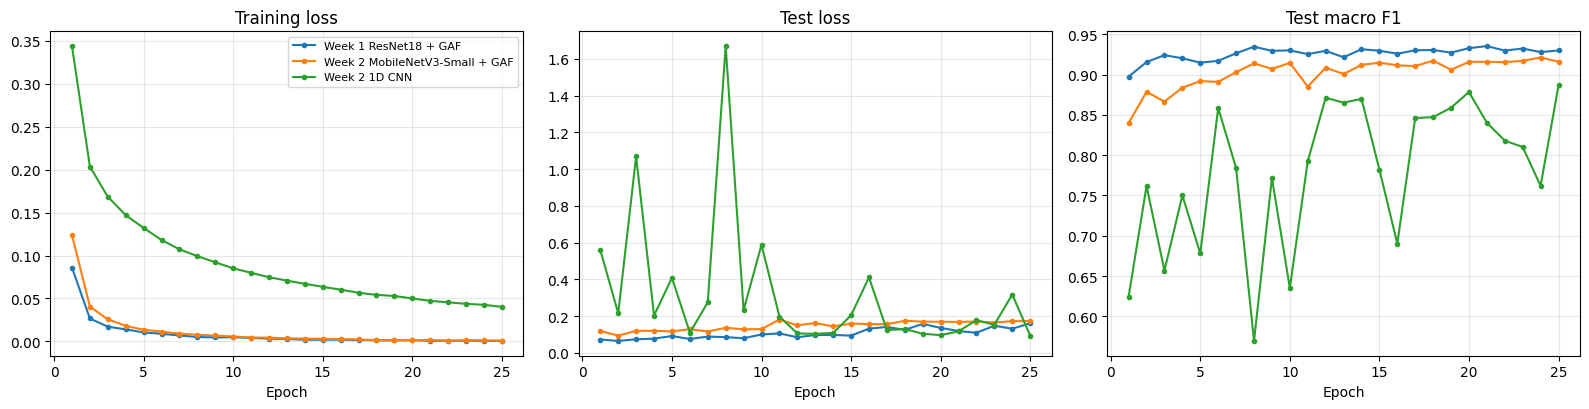

Kurva tersedia untuk: ['Week 1 ResNet18 + GAF', 'Week 2 MobileNetV3-Small + GAF', 'Week 2 1D CNN']


In [76]:
curves = {"Week 1 ResNet18 + GAF": baseline_history,
          "Week 2 MobileNetV3-Small + GAF": hist_mobilenet,
          "Week 2 1D CNN": hist_1dcnn}
curves = {k: v for k, v in curves.items() if v is not None}

if not curves:
    print(NOT_RUN, "— belum ada history.")
else:
    fig_lc, axes = plt.subplots(1, 3, figsize=(16, 4.2))
    for label, h in curves.items():
        axes[0].plot(h["epoch"], h["train_loss"], marker=".", label=label)
        axes[1].plot(h["epoch"], h["test_loss"], marker=".", label=label)
        axes[2].plot(h["epoch"], h["test_f1"], marker=".", label=label)
    for ax, title in zip(axes, ["Training loss", "Test loss", "Test macro F1"]):
        ax.set_title(title); ax.set_xlabel("Epoch"); ax.grid(alpha=0.3)
    axes[0].legend(fontsize=8)
    plt.tight_layout()
    fig_lc.savefig(week2_path(FIGURES_DIR, "week2_learning_curves.png"), dpi=150, bbox_inches="tight")
    plt.show()
print("Kurva tersedia untuk:", list(curves) or NOT_RUN)

# Section 17 — Experiment Log

Ditulis ke `outputs/results/week2_experiment_log.json`. Versi paket dibaca dari environment yang sedang berjalan (bukan ditebak). Sel ini juga memeriksa ulang snapshot artifact Week 1 dari Section 3.

In [77]:
def installed_version(dist_name):
    try:
        return pkg_version(dist_name)
    except PackageNotFoundError:
        return "NOT INSTALLED"


def run_log(tag, history, best, final, params, config, num_epochs):
    status = training_status(tag, num_epochs)
    log = {"status": status, "config": config, "params": params,
           "batch_size": BATCH_SIZE, "epochs": num_epochs}
    if history is None:
        log.update(training_time_sec=NOT_RUN if status == NOT_RUN else NOT_RECORDED)
    else:
        log.update(training_time_sec=float(history["epoch_time_sec"].sum()),
                   training_time_per_epoch_sec=float(history["epoch_time_sec"].mean()))
    for name, m in (("best_f1_checkpoint", best), ("final_epoch", final)):
        log[name] = NOT_RUN if m is None else {k: (int(v) if k == "epoch" else float(v)) for k, v in m.items()
                                                if k in ("accuracy", "precision", "recall", "f1", "epoch")}
    return log


week1_after = snapshot(WEEK1_READONLY)
week1_unchanged = week1_after == WEEK1_SNAPSHOT
inference_by_method = table_complexity.set_index("Method")[["Inference ms / batch64", "Inference ms / sample"]]

experiment_log = {
    "timestamp_utc": datetime.now(timezone.utc).isoformat(),
    "seed": SEED,
    "environment": {
        "python": sys.version.split()[0],
        "platform": platform.platform(),
        "torch": torch.__version__,
        "torchvision": torchvision.__version__,
        "scikit-learn": sklearn.__version__,
        "imbalanced-learn": installed_version("imbalanced-learn"),
        "numpy": np.__version__,
        "h5py": h5py.__version__,
        "cuda": torch.version.cuda if torch.cuda.is_available() else "NOT AVAILABLE",
        "cudnn": torch.backends.cudnn.version() if torch.cuda.is_available() else "NOT AVAILABLE",
        "gpu": torch.cuda.get_device_name(0) if torch.cuda.is_available() else "NOT AVAILABLE",
    },
    "note_imbalanced_learn": "Week 2 tidak menjalankan SMOTE; artifact SMOTE Week 1 dipakai apa adanya. "
                             "Versi di atas = paket terpasang di runtime ini, belum tentu sama dengan saat SMOTE dibuat.",
    "dataset": {
        "source": "MIT-BIH (Kaggle shayanfazeli/heartbeat), split resmi",
        "raw_train": [N_TRAIN, N_SAMPLES], "raw_test": [N_TEST, N_SAMPLES],
        "gaf_train": [N_TRAIN, 224, 224], "gaf_test": [N_TEST, 224, 224],
        "train_class_counts": EXPECTED_TRAIN_COUNTS,
        "smoke_subset": {"train": int(len(SMOKE_IDX_TRAIN)), "test": int(len(SMOKE_IDX_TEST))},
    },
    "shared_training": {
        "batch_size": BATCH_SIZE, "epochs_full": NUM_EPOCHS_FULL, "epochs_smoke": NUM_EPOCHS_SMOKE,
        "loss": f"CrossEntropyLoss(weight={CLASS_WEIGHTS})", "optimizer": f"Adam betas={ADAM_BETAS}",
        "scheduler": f"ExponentialLR(gamma={LR_GAMMA}), step per epoch",
        "checkpoint_selection": "macro-F1 terbaik pada test set (sama dengan Week 1)",
    },
    "baseline_week1": {
        "source": baseline_source, "params": BASELINE_PARAMS,
        "best_f1_checkpoint": NOT_RUN if baseline_best is None else
            {k: (int(v) if k == "epoch" else float(v)) for k, v in baseline_best.items()
             if k in ("accuracy", "precision", "recall", "f1", "epoch")},
        "training_time_sec": NOT_RECORDED,
    },
    "mobilenet_v3_small": run_log("mobilenet", hist_mobilenet, mobilenet_best, mobilenet_final,
                                  MOBILENET_PARAMS, MOBILENET_CONFIG, NUM_EPOCHS_FULL),
    "cnn_1d": run_log("1dcnn", hist_1dcnn, cnn1d_best, cnn1d_final, CNN1D_PARAMS, CNN1D_CONFIG, NUM_EPOCHS_FULL),
    "inference_compute_only": {"device": INFERENCE_DEVICE, "batch_size": BATCH_SIZE,
                               **{k: {"ms_per_batch": float(v["Inference ms / batch64"]),
                                      "ms_per_sample": float(v["Inference ms / sample"])}
                                  for k, v in inference_by_method.iterrows()}},
    "flags": {"RUN_MOBILENET_SMOKE": RUN_MOBILENET_SMOKE, "RUN_MOBILENET_FULL": RUN_MOBILENET_FULL,
              "RUN_1D_SMOKE": RUN_1D_SMOKE, "RUN_1D_FULL": RUN_1D_FULL},
    "deviations": ["D1 head MobileNet: hanya layer terakhir diganti", "D2 MobileNet features[0:4] beku",
                   "D3 MobileNet LR 1e-4/2e-3", "D4 1D CNN LR 1e-3 dari nol + BatchNorm",
                   "D5 tanpa validation set (seleksi pada test set, sama dengan Week 1)",
                   "D6 dropout 0.2 bawaan MobileNetV3"],
    "week1_artifacts_unchanged": week1_unchanged,
}

LOG_JSON = week2_path(RESULTS_DIR, "week2_experiment_log.json")
with open(LOG_JSON, "w") as fh:
    json.dump(experiment_log, fh, indent=2, default=str)
print("Saved:", LOG_JSON)
print("Artifact Week 1 tidak berubah:", week1_unchanged)
if not week1_unchanged:
    raise RuntimeError("Artifact Week 1 BERUBAH selama sesi ini — periksa sebelum melanjutkan.")

Saved: /content/drive/MyDrive/Projek PSD/ECG_Multimodal_Fusion/outputs/results/week2_experiment_log.json
Artifact Week 1 tidak berubah: True


# Section 18 — Week 2 Conclusion

Sel di bawah menjawab enam pertanyaan **langsung dari angka** di Tabel 1–3 dan Section 15 (tidak ada nilai yang ditulis tangan). Jika suatu model belum dijalankan, jawabannya `NOT RUN`.

Aturan interpretasi yang ditetapkan **sebelum** melihat hasil:
- Model utama dibandingkan dengan **Macro F1** (data uji tidak seimbang; accuracy didominasi kelas N).
- "Mendekati/sebanding" = selisih Macro F1 ≤ **1,0 poin persen** terhadap ResNet18 + GAF. Ini ambang deskriptif, **bukan uji signifikansi** (uji signifikansi dikerjakan di Week 3).
- Hasil Tabel 1 memakai seleksi checkpoint pada test set (optimistis); kesimpulan juga dicek terhadap Tabel 2 (epoch terakhir).

Keterbatasan yang sudah diketahui:
- Satu run per model (satu seed) → belum ada estimasi variansi.
- LR Model A/B tidak di-tuning (deviasi D3–D4); hasil buruk bisa berarti konfigurasi, bukan batas kemampuan arsitektur.
- Perbandingan B vs baseline mengubah **dua** hal sekaligus (representasi input dan arsitektur) — itu memang sifat pertanyaan eksperimen B; hasilnya tidak bisa diatribusikan ke salah satu faktor saja.

In [78]:
THRESHOLD_PP = 1.0


def has(m):
    return m is not None


def pp(a, b):
    return 100 * (float(a) - float(b))


def answer_close(label, m, ref, ref_label):
    if not has(m) or not has(ref):
        return f"{NOT_RUN} ({label}: {'ada' if has(m) else 'belum'}, {ref_label}: {'ada' if has(ref) else 'belum'})"
    d = pp(m["f1"], ref["f1"])
    verdict = "YA, mendekati" if abs(d) <= THRESHOLD_PP else ("TIDAK, lebih rendah" if d < 0 else "TIDAK, lebih tinggi")
    return f"{verdict}: Macro F1 {float(m['f1']):.4f} vs {float(ref['f1']):.4f} (selisih {d:+.2f} pp, ambang ±{THRESHOLD_PP} pp)"


answers = {}
for table_name, idx in (("Tabel 1 (best-F1 checkpoint)", 2), ("Tabel 2 (epoch terakhir)", 3)):
    b, mob, cnn = (m[idx] for m in METHODS)
    print(f"\n===== {table_name} =====")
    print("1. MobileNetV3-Small vs ResNet18 (GAF):", answer_close("MobileNet", mob, b, "ResNet18"))
    print("2. 1D CNN raw vs ResNet18 + GAF      :", answer_close("1D CNN", cnn, b, "ResNet18"))
    if has(mob):
        print("   1D CNN raw vs MobileNet + GAF     :", answer_close("1D CNN", cnn, mob, "MobileNet"))

    available = {m[0]: m[idx] for m in METHODS if has(m[idx])}
    if len(available) < 2:
        print("3. Model terbaik (Macro F1)          :", NOT_RUN, "(kurang dari 2 model tersedia)")
        print("4. Accuracy vs Macro F1              :", NOT_RUN)
    else:
        by_f1 = sorted(available, key=lambda k: float(available[k]["f1"]), reverse=True)
        by_acc = sorted(available, key=lambda k: float(available[k]["accuracy"]), reverse=True)
        print("3. Model terbaik (Macro F1)          :", by_f1[0], f"({float(available[by_f1[0]]['f1']):.4f})")
        print("   Urutan Macro F1                   :", " > ".join(by_f1))
        print("4. Urutan Accuracy                   :", " > ".join(by_acc))
        print("   Kesimpulan sama?                  :",
              "YA, urutan identik" if by_f1 == by_acc else
              "TIDAK — urutan berbeda; kesimpulan mengikuti Macro F1, bukan accuracy")
    answers[table_name] = {"methods": list(available)}

print("\n5. Confusion matrix — recall per kelas (Section 15):")
if len(per_class_recall):
    for _, r in per_class_recall.iterrows():
        worst = min(CLASS_NAMES, key=lambda c: r[c])
        print(f"   {r['Method']:32s} recall terendah: kelas {worst} ({r[worst]:.4f}); "
              + ", ".join(f"{c}={r[c]:.3f}" for c in CLASS_NAMES))
else:
    print("  ", NOT_RUN)

print("\n6. Trade-off performa vs kompleksitas (Tabel 3):")
for _, r in table_complexity.iterrows():
    best = next(m[2] for m in METHODS if m[0] == r["Method"])
    f1_txt = NOT_RUN if not has(best) else f"{float(best['f1']):.4f}"
    train_t = r["Train time total (min)"]
    train_txt = train_t if isinstance(train_t, str) else f"{train_t:.1f} min"
    print(f"   {r['Method']:32s} params={int(r['Params total']):>11,d} "
          f"(trainable {int(r['Params trainable']):>10,d}) | infer {r['Inference ms / sample']:.4f} ms/sampel | "
          f"train {train_txt} | Macro F1 {f1_txt}")


===== Tabel 1 (best-F1 checkpoint) =====
1. MobileNetV3-Small vs ResNet18 (GAF): TIDAK, lebih rendah: Macro F1 0.9211 vs 0.9353 (selisih -1.42 pp, ambang ±1.0 pp)
2. 1D CNN raw vs ResNet18 + GAF      : TIDAK, lebih rendah: Macro F1 0.8864 vs 0.9353 (selisih -4.89 pp, ambang ±1.0 pp)
   1D CNN raw vs MobileNet + GAF     : TIDAK, lebih rendah: Macro F1 0.8864 vs 0.9211 (selisih -3.47 pp, ambang ±1.0 pp)
3. Model terbaik (Macro F1)          : Week 1 ResNet18 + GAF (0.9353)
   Urutan Macro F1                   : Week 1 ResNet18 + GAF > Week 2 MobileNetV3-Small + GAF > Week 2 1D CNN
4. Urutan Accuracy                   : Week 1 ResNet18 + GAF > Week 2 MobileNetV3-Small + GAF > Week 2 1D CNN
   Kesimpulan sama?                  : YA, urutan identik

===== Tabel 2 (epoch terakhir) =====
1. MobileNetV3-Small vs ResNet18 (GAF): TIDAK, lebih rendah: Macro F1 0.9160 vs 0.9299 (selisih -1.38 pp, ambang ±1.0 pp)
2. 1D CNN raw vs ResNet18 + GAF      : TIDAK, lebih rendah: Macro F1 0.8864 vs 0.9299 

### Kesimpulan

Pada Week 2 dilakukan dua eksperimen pembanding terhadap baseline Week 1, yaitu **MobileNetV3-Small + GAF** dan **1D CNN + sinyal ECG mentah**. Perbandingan dilakukan menggunakan Accuracy dan terutama Macro F1, karena dataset uji memiliki distribusi kelas yang tidak seimbang. Berdasarkan hasil pengujian, baseline **ResNet18 + GAF** masih memberikan performa terbaik, tetapi kedua metode pembanding menunjukkan keunggulan pada aspek kompleksitas model dan waktu inferensi.

Hasil utama eksperimen adalah sebagai berikut:

- **ResNet18 + GAF** memperoleh Macro F1 sebesar **93,53%** dan menjadi model dengan performa terbaik.
- **MobileNetV3-Small + GAF** memperoleh Macro F1 sebesar **92,11%**, atau **1,42 poin persentase lebih rendah** daripada baseline. Dengan ambang deskriptif ±1 poin persentase yang ditetapkan dalam eksperimen, MobileNet belum dapat dianggap sebanding dengan baseline.
- **1D CNN + raw ECG** memperoleh Macro F1 sebesar **88,64%**, atau **4,89 poin persentase lebih rendah** daripada baseline dan **3,47 poin persentase lebih rendah** daripada MobileNetV3-Small.
- Urutan performa berdasarkan **Macro F1 maupun Accuracy** tetap sama, yaitu **ResNet18 + GAF > MobileNetV3-Small + GAF > 1D CNN**. Hasil pada epoch terakhir juga menunjukkan urutan yang sama.
- Dari sisi kompleksitas, **MobileNetV3-Small** memiliki sekitar **1,52 juta parameter**, jauh lebih sedikit dibandingkan ResNet18 yang memiliki sekitar **11,34 juta parameter**. **1D CNN** memiliki kompleksitas paling rendah dengan sekitar **36 ribu parameter**.
- Waktu inferensi juga lebih rendah pada model pembanding: sekitar **0,215 ms/sampel untuk MobileNetV3-Small** dan **0,012 ms/sampel untuk 1D CNN**, dibandingkan sekitar **0,797 ms/sampel untuk ResNet18**.
- Pada tingkat kelas, kelemahan terbesar masih terlihat pada kelas minoritas. Recall terendah terdapat pada kelas **S untuk ResNet18 (81,83%)**, **F untuk MobileNetV3-Small (79,63%)**, dan **S untuk 1D CNN (74,10%)**.

Secara keseluruhan, hasil Week 2 menunjukkan bahwa **penggunaan arsitektur yang lebih ringan maupun penggunaan sinyal ECG secara langsung belum menghasilkan performa klasifikasi yang lebih baik dibandingkan ResNet18 + GAF pada konfigurasi eksperimen ini**. Namun, MobileNetV3-Small dan terutama 1D CNN memberikan trade-off berupa jumlah parameter dan waktu inferensi yang jauh lebih rendah. Hasil ini menunjukkan bahwa pemilihan model tidak hanya bergantung pada akurasi, tetapi juga pada kebutuhan efisiensi komputasi.

Perlu dicatat bahwa eksperimen ini masih menggunakan **satu kali run dengan satu seed**, sehingga belum memberikan estimasi variasi hasil. Selain itu, hasil MobileNetV3-Small dan 1D CNN menggunakan konfigurasi learning rate tertentu yang belum melalui tuning, sehingga performa yang lebih rendah belum dapat dianggap sebagai batas kemampuan arsitekturnya. Pengujian signifikansi dan analisis lebih lanjut akan dilakukan pada **Week 3**.